# QLoRA demo — vision (MLX, Apple Silicon)

Fine-tune the **vision-language** Qwen3.5-2B on receipt images from [CORD-v2](https://huggingface.co/datasets/naver-clova-ix/cord-v2): image in, line items + total out as JSON.

Same recipe as `QLoRA_demo_mlx.ipynb`, using `mlx-vlm` instead of `mlx-lm` so the vision tower is loaded:
- language model quantized to 4-bit; vision tower and `lm_head` kept in full precision (like `llm_int8_skip_modules=["visual", "lm_head"]`)
- LoRA `r=16, alpha=32, dropout=0.05` on the language model's linear layers
- loss only on the answer (`train_on_completions=True`)
- only `N_TRAIN` receipts, streamed so the full 1.8 GB train split is not downloaded

**Setup** (once, from this folder):

```bash
uv venv .venv && uv pip install --python .venv/bin/python mlx-vlm datasets ipykernel
```

Then select the `.venv` kernel for this notebook.

In [1]:
import json
import mlx.nn as nn
from datasets import load_dataset
from mlx_vlm import load, generate
from mlx_vlm.prompt_utils import apply_chat_template
from mlx_vlm.trainer import Trainer, VLMTrainingArgs, get_peft_model

MODEL_ID = "Qwen/Qwen3.5-2B"

model, processor = load(MODEL_ID)

nn.quantize(
    model.language_model, group_size=64, bits=4,
    class_predicate=lambda path, m: isinstance(m, nn.Linear) and not path.endswith("lm_head") and m.weight.shape[-1] % 64 == 0,
)

/Users/gokularajan/Desktop/gulu/yuvan/QLORA_DEMO/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 10 files: 100%|██████████| 10/10 [04:50<00:00, 29.02s/it]


{"items": [{"name": "Nasi Campur Bali", "qty": "1 x", "price": "75,000"}, {"name": "Bbk Bengil Nasi", "qty": "1 x", "price": "125,000"}, {"name": "MilkShake Starwb", "qty": "1 x", "price": "37,000"}, {"name": "Ice Lemon Tea", "qty": "1 x", "price": "24,000"}, {"name": "Nasi Ayam Dewata", "qty": "1 x", "price": "70,000"}, {"name": "Free Ice Tea", "qty": "3 x", "price": "0"}, {"name": "Organic Green Sa", "qty": "1 x", "price": "65,000"}, {"name": "Ice Tea", "qty": "1 x", "price": "18,000"}, {"name": "Ice Orange", "qty": "1 x", "price": "29,000"}, {"name": "Ayam Suir Bali", "qty": "1 x", "price": "85,000"}, {"name": "Tahu Goreng", "qty": "2 x", "price": "36,000"}, {"name": "Tempe Goreng", "qty": "2 x", "price": "36,000"}, {"name": "Tahu Telor Asin", "qty": "1 x", "price": "40,000."}, {"name": "Nasi Goreng Samb", "qty": "1 x", "price": "70,000"}, {"name": "Bbk Panggang Sam", "qty": "3 x", "price": "366,000"}, {"name": "Ayam Sambal Hija", "qty": "1 x", "price": "92,000"}, {"name": "Hot Tea"

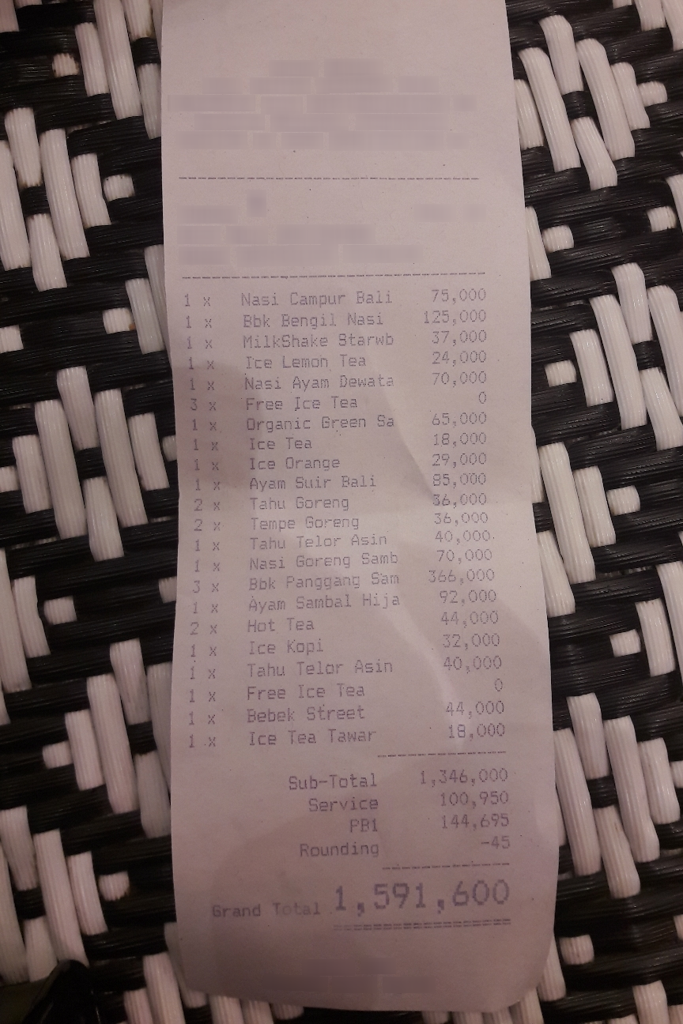

In [2]:
N_TRAIN = 20     # keep the demo small
N_TEST = 3
MAX_SIDE = 1024  # downscale receipts: fewer image tokens, less memory

PROMPT = "Extract the line items and the total from this receipt. Respond with JSON only."

def target(ground_truth):
    """CORD's nested gt_parse -> a compact {"items": [...], "total": ...} answer."""
    gt = json.loads(ground_truth)["gt_parse"]
    menu = gt.get("menu", [])
    menu = menu if isinstance(menu, list) else [menu]
    items = []
    for m in menu:
        item = {k: m[src] for k, src in (("name", "nm"), ("qty", "cnt"), ("price", "price")) if src in m}
        items.append({k: " ".join(v) if isinstance(v, list) else v for k, v in item.items()})
    total = gt.get("total", {})
    total = total.get("total_price") if isinstance(total, dict) else None
    return json.dumps({"items": items, "total": total}, ensure_ascii=False)

def shrink(img):
    img = img.convert("RGB")
    img.thumbnail((MAX_SIDE, MAX_SIDE))
    return img

def rows(split, n):
    for r in load_dataset("naver-clova-ix/cord-v2", split=split, streaming=True).take(n):
        yield {"images": [shrink(r["image"])], "answer": target(r["ground_truth"])}

train_rows = [
    {"images": r["images"], "messages": [
        {"role": "user", "content": PROMPT},
        {"role": "assistant", "content": r["answer"]},
    ]}
    for r in rows("train", N_TRAIN)
]
test_rows = list(rows("test", N_TEST))

print(train_rows[0]["messages"][1]["content"])
train_rows[0]["images"][0]

In [3]:
def extract(img, max_new_tokens=400):
    prompt = apply_chat_template(processor, model.config, PROMPT, num_images=1)
    # greedy decoding by default (same as do_sample=False)
    return generate(model, processor, prompt, image=[img], max_tokens=max_new_tokens, verbose=False).text.strip()

def show(tag):
    for i, r in enumerate(test_rows):
        print(f"[{i}] {tag}:", extract(r["images"][0]))
        print(f"[{i}] TRUTH: ", r["answer"], end="\n\n")

show("BEFORE")

[0] BEFORE: ```json
{
  "line_items": [
    {
      "description": "TICKET CP",
      "quantity": 2,
      "unit_price": 60.00,
      "total": 120.00
    }
  ],
  "total": 60.00
}
```
[0] TRUTH:  {"items": [{"name": "-TICKET CP", "qty": "2", "price": "60.000"}], "total": "60.000"}

[1] BEFORE: ```json
{
  "line_items": [
    {
      "name": "J.STB PROMO",
      "amount": 17500
    },
    {
      "name": "Y.B.BAT",
      "amount": 46000
    },
    {
      "name": "Y.BASO PROM",
      "amount": 27500
    }
  ],
  "total": 91000
}
```
[1] TRUTH:  {"items": [{"name": "J.STB PROMO", "price": "17500"}, {"name": "Y.B.BAT", "price": "46000"}, {"name": "Y.BASO PROM", "price": "27500"}], "total": "91000"}

[2] BEFORE: ```json
{
  "line_items": [
    {
      "name": "JASMINE MT (L)",
      "quantity": 1,
      "unit_price": 24.000,
      "total": 24.000
    },
    {
      "name": "COCONUT JELLY (L)",
      "quantity": 1,
      "unit_price": 4.000,
      "total": 4.000
    }
  ],
  "total": 28.000

In [4]:
model = get_peft_model(model, rank=16, alpha=32, dropout=0.05)   # freezes the base, LoRA on language-model linears

EPOCHS = 2
args = VLMTrainingArgs(
    iters=EPOCHS * N_TRAIN,          # batch_size=1 -> one receipt per step
    batch_size=1,
    learning_rate=2e-4,
    train_on_completions=True,       # loss only on the answer
    grad_checkpoint=True,            # long image-token sequences; trade compute for memory
    steps_per_report=5,
    steps_per_eval=None,
    steps_per_save=10_000,           # only save at the end
    adapter_file="qwen35-2b-cord-lora/adapters.safetensors",
)

trainer = Trainer(model, args, train_dataset=train_rows, processing_class=processor)
trainer.train()

trainable params: 16.8192 M || all params: 2213.241088 M || trainable%: 0.760%


Training:  12%|█▎        | 5/40 [00:43<04:34,  7.85s/it, loss=0.1224, lr=2.00e-04]

Training (iteration 5):
optimizer_step=5, train_loss=0.12237, train_nll=0.12237, train_token_accuracy=0.97893
train_num_padded_tokens=138, train_num_processed_tokens=4,177, train_num_sequences=5, train_num_tokens=949
train_num_vision_tokens=3,078, train_perplexity=1.1302, learning_rate=0.0002, iterations_per_second=0.11794
optimizer_steps_per_second=0.11794, tokens_per_second=22.386, trained_tokens=949, step_time=8.4785
data_time_per_step=0.13046, train_time=42.393, data_time=0.65229, elapsed_time=43.072
remaining_time=301.5, progress=0.125, peak_memory=7.5446, active_memory=2.9608
cache_memory=9.106, total_padded_tokens=138, padded_tokens_per_second=3.2553, total_processed_tokens=4,177
processed_tokens_per_second=98.531, total_sequences=5, sequences_per_second=0.11794, total_tokens=949
total_vision_tokens=3,078, vision_tokens_per_second=72.607, processed_tokens=4,177, end_to_end_tokens_per_second=97.038
padding_fraction=0.031981, average_sequence_length=835.4


Training:  25%|██▌       | 10/40 [01:16<03:24,  6.81s/it, loss=0.1210, lr=2.00e-04]

Training (iteration 10):
optimizer_step=10, train_loss=0.12098, train_nll=0.12098, train_token_accuracy=0.96514
train_num_padded_tokens=84, train_num_processed_tokens=3,783, train_num_sequences=5, train_num_tokens=459
train_num_vision_tokens=3,174, train_perplexity=1.1286, learning_rate=0.0002, iterations_per_second=0.14781
optimizer_steps_per_second=0.14781, tokens_per_second=13.569, trained_tokens=1,408, step_time=6.7653
data_time_per_step=0.00091525, train_time=76.219, data_time=0.65686, elapsed_time=76.921
remaining_time=230.76, progress=0.25, peak_memory=7.5446, active_memory=2.9608
cache_memory=8.8605, total_padded_tokens=222, padded_tokens_per_second=2.4833, total_processed_tokens=7,960
processed_tokens_per_second=111.84, total_sequences=10, sequences_per_second=0.14781, total_tokens=1,408
total_vision_tokens=6,252, vision_tokens_per_second=93.832, processed_tokens=7,960, end_to_end_tokens_per_second=111.82
padding_fraction=0.021722, average_sequence_length=756.6


...

Training:  88%|████████▊ | 35/40 [04:56<00:53, 10.72s/it, loss=0.3991, lr=2.00e-04]

Training (iteration 35):
optimizer_step=35, train_loss=0.39911, train_nll=0.39911, train_token_accuracy=0.9226
train_num_padded_tokens=119, train_num_processed_tokens=4,324, train_num_sequences=5, train_num_tokens=814
train_num_vision_tokens=3,360, train_perplexity=1.4905, learning_rate=0.0002, iterations_per_second=0.092447
optimizer_steps_per_second=0.092447, tokens_per_second=15.05, trained_tokens=4,507, step_time=10.817
data_time_per_step=0.0010016, train_time=295.5, data_time=0.69248, elapsed_time=296.3
remaining_time=42.329, progress=0.875, peak_memory=7.6245, active_memory=2.9608
cache_memory=8.3456, total_padded_tokens=686, padded_tokens_per_second=2.2002, total_processed_tokens=27,279
processed_tokens_per_second=79.948, total_sequences=35, sequences_per_second=0.092447, total_tokens=4,507
total_vision_tokens=21,724, vision_tokens_per_second=62.124, processed_tokens=27,279, end_to_end_tokens_per_second=79.94
padding_fraction=0.026784, average_sequence_length=864.8


Training: 100%|██████████| 40/40 [05:39<00:00,  8.48s/it, loss=0.2207, lr=2.00e-04]


Training (iteration 40):
optimizer_step=40, train_loss=0.22072, train_nll=0.22072, train_token_accuracy=0.94272
train_num_padded_tokens=44, train_num_processed_tokens=3,631, train_num_sequences=5, train_num_tokens=611
train_num_vision_tokens=2,872, train_perplexity=1.247, learning_rate=0.0002, iterations_per_second=0.11655
optimizer_steps_per_second=0.11655, tokens_per_second=14.242, trained_tokens=5,118, step_time=8.5804
data_time_per_step=0.0015112, train_time=338.4, data_time=0.70004, elapsed_time=339.24
remaining_time=0, progress=1, peak_memory=7.6245, active_memory=2.9608
cache_memory=9.1151, total_padded_tokens=730, padded_tokens_per_second=1.0256, total_processed_tokens=30,910
processed_tokens_per_second=84.635, total_sequences=40, sequences_per_second=0.11655, total_tokens=5,118
total_vision_tokens=24,596, vision_tokens_per_second=66.943, processed_tokens=30,910, end_to_end_tokens_per_second=84.62
padding_fraction=0.011973, average_sequence_length=726.2
Saved final trainable we

{'iteration': 40,
 'optimizer_step': 40,
 'train_loss': 0.2207243524479593,
 'train_nll': 0.2207243524479593,
 'train_token_accuracy': 0.9427168576104746,
 'train_num_padded_tokens': 44,
 'train_num_processed_tokens': 3631,
 'train_num_sequences': 5,
 'train_num_tokens': 611,
 'train_num_vision_tokens': 2872,
 'train_perplexity': 1.2469796562962712,
 'learning_rate': 0.00019999999494757503,
 'iterations_per_second': 0.11654503695229212,
 'optimizer_steps_per_second': 0.11654503695229212,
 'tokens_per_second': 14.241803515570098,
 'trained_tokens': 5118,
 'step_time': 8.580373958003474,
 'data_time_per_step': 0.001511166599811986,
 'train_time': 338.39954291295726,
 'data_time': 0.7000378360098694,
 'elapsed_time': 339.41508325000177,
 'remaining_time': 0.0,
 'progress': 1.0,
 'peak_memory': 7.62448631,
 'active_memory': 2.960826143,
 'cache_memory': 9.115145716,
 'total_padded_tokens': 730,
 'padded_tokens_per_second': 1.0255963251801707,
 'total_processed_tokens': 30910,
 'processed_t

In [5]:
model.eval()
show("AFTER")

trainer.save_adapter()   # adapter only, ~tens of MB; reload with mlx_vlm.load(MODEL_ID, adapter_path="qwen35-2b-cord-lora")

[0] AFTER: {"items": [{"name": "TETRAPIZA", "qty": "2", "price": "60,000"}], "total": "60,000"}
[0] TRUTH:  {"items": [{"name": "-TICKET CP", "qty": "2", "price": "60.000"}], "total": "60.000"}

[1] AFTER: {"items": [{"name": "J. STB PROMO", "qty": "1", "price": "17500"}], "total": "91000"}
[1] TRUTH:  {"items": [{"name": "J.STB PROMO", "price": "17500"}, {"name": "Y.B.BAT", "price": "46000"}, {"name": "Y.BASO PROM", "price": "27500"}], "total": "91000"}

[2] AFTER: {"items": [{"name": "JASMINE MT", "qty": "1", "price": "24,000"}], "total": "28,000"}
[2] TRUTH:  {"items": [{"name": "JASMINE MT ( L )", "qty": "1", "price": "24,000"}], "total": "28,000"}

Saved final trainable weights to qwen35-2b-cord-lora/adapters.safetensors.
